# Batch culture: 25 species, one starting resource, two cross-fed metabolites

Run all cells from this project folder. Parameters are normalized exploratory values, not measured bacterial rates. See README.md for all equations and assumptions. The notebook uses the same scripts as the command-line simulation.

In [1]:
from pathlib import Path
from dataclasses import replace
import numpy as np
import pandas as pd
from IPython.display import display, Image
from model import Config, generate, simulate, summarize, export
from plots import make_plots, ensemble, ensemble_plot
config = Config(seed=42)
out = Path("outputs")
config

Config(seed=42, n_species=25, t_end=300.0, n_times=1201, growth_mean=0.5, growth_sd=0.15, growth_reference=1.0, death_mean=0.01, death_sd=0.003, initial_biomass=0.01, initial_resource=1.0, half_saturation=0.1, leakage=0.2, extinction_fraction=1e-06)

## Generate and characterize the community
Growth-capacity scores and death rates are independently sampled truncated Gaussians. Food subsets and secretion partitions are sampled once, not at each time step. Metabolite-only consumers begin without food. Maximum growth is normalized across different uptake profiles.

In [2]:
community = generate(config)
display(community["table"])
columns=["growth_score", "mu_max", "death_rate", "total_uptake_capacity", "M1_secretion_share", "M2_secretion_share"]
spread=community["table"][columns].describe().T
spread["median"]=community["table"][columns].median()
out.mkdir(exist_ok=True)
spread.to_csv(out / "realized_parameter_spread.csv")
display(spread)
permissions=community["table"][["can_consume_R0", "can_consume_M1", "can_consume_M2"]].value_counts().rename("species_count")
display(permissions)

,species,growth_score,mu_max,death_rate,total_uptake_capacity,M1_secretion_share,M2_secretion_share,initial_biomass,can_consume_R0,preference_R0,uptake_max_R0,can_consume_M1,preference_M1,uptake_max_M1,can_consume_M2,preference_M2,uptake_max_M2
0,S01,0.612674,0.612674,0.007421,0.765842,0.851535,0.148465,0.0004,True,1.000000,0.765842,False,0.000000,0.000000,False,0.000000,0.000000
1,S02,0.476948,0.476948,0.009751,0.476948,0.774623,0.225377,0.0004,False,0.000000,0.000000,True,1.000000,0.476948,False,0.000000,0.000000
2,S03,0.660900,0.660900,0.004889,0.660900,0.777048,0.222952,0.0004,False,0.000000,0.000000,False,0.000000,0.000000,True,1.000000,0.660900
3,S04,0.577454,0.577454,0.006950,0.721818,0.596019,0.403981,0.0004,True,1.000000,0.721818,False,0.000000,0.000000,False,0.000000,0.000000
4,S05,0.302991,0.302991,0.011430,0.302991,0.614703,0.385297,0.0004,False,0.000000,0.000000,True,0.756683,0.229268,True,0.243317,0.073723
5,S06,0.794546,0.794546,0.011975,0.794546,0.955243,0.044757,0.0004,False,0.000000,0.000000,True,0.364302,0.289455,True,0.635698,0.505092
6,S07,0.606388,0.606388,0.015537,0.606388,0.387466,0.612534,0.0004,False,0.000000,0.000000,True,0.485439,0.294364,True,0.514561,0.312023
7,S08,0.618800,0.618800,0.008648,0.626843,0.145785,0.854215,0.0004,True,0.064157,0.040217,False,0.000000,0.000000,True,0.935843,0.586626
8,S09,0.329925,0.329925,0.009010,0.329925,0.056926,0.943074,0.0004,False,0.000000,0.000000,False,0.000000,0.000000,True,1.000000,0.329925
9,S10,0.481313,0.481313,0.009773,0.493816,0.352711,0.647289,0.0004,True,0.126598,0.062516,False,0.000000,0.000000,True,0.873402,0.431300


,count,mean,std,min,25%,50%,75%,max,median
growth_score,25.0,0.552315,0.138293,0.271924,0.476948,0.577454,0.638731,0.794546,0.577454
mu_max,25.0,0.552315,0.138293,0.271924,0.476948,0.577454,0.638731,0.794546,0.577454
death_rate,25.0,0.009677,0.002487,0.004889,0.007756,0.009527,0.011430,0.015537,0.009527
total_uptake_capacity,25.0,0.587315,0.150968,0.302991,0.478671,0.614891,0.686220,0.899148,0.614891
M1_secretion_share,25.0,0.544626,0.271063,0.056926,0.371568,0.596019,0.774623,0.955243,0.596019
M2_secretion_share,25.0,0.455374,0.271063,0.044757,0.225377,0.403981,0.628432,0.943074,0.403981


can_consume_R0  can_consume_M1  can_consume_M2
False           False           True              8
                True            True              5
True            False           False             5
                                True              4
False           True            False             3
Name: species_count, dtype: int64

## Integrate the batch
The starting nutrient is finite. Only consumption of R0 generates M1/M2. No chemical decays or replenishes. Constant death removes biomass to an accounting sink. Threshold crossings irreversibly remove species.

In [3]:
result=simulate(community)
summary=summarize(community,result)
export(community,result,out)
figures=make_plots(community,result,out)
print("Survivors:", int(summary.survived.sum()), "/", config.n_species)
print("Maximum budget error:", abs(result["budget_error"]).max())
display(summary[["species", "mu_max", "death_rate", "peak_biomass", "final_biomass", "final_percent", "extinction_time", "survived"]])

Survivors: 25 / 25
Maximum budget error: 1.517452830057664e-12


,species,mu_max,death_rate,peak_biomass,final_biomass,final_percent,extinction_time,survived
0,S01,0.612674,0.007421,0.268432,0.031966,35.093531,NaN,True
1,S02,0.476948,0.009751,0.011730,0.000859,0.943157,NaN,True
2,S03,0.660900,0.004889,0.002171,0.000565,0.619998,NaN,True
3,S04,0.577454,0.006950,0.184751,0.025183,27.646692,NaN,True
4,S05,0.302991,0.011430,0.002040,0.000094,0.102678,NaN,True
5,S06,0.794546,0.011975,0.010381,0.000413,0.453031,NaN,True
6,S07,0.606388,0.015537,0.005734,0.000087,0.095232,NaN,True
7,S08,0.618800,0.008648,0.002310,0.000211,0.231672,NaN,True
8,S09,0.329925,0.009010,0.000809,0.000066,0.072680,NaN,True
9,S10,0.481313,0.009773,0.001795,0.000119,0.130921,NaN,True


## Species traits and batch dynamics
Colors consistently identify species in trajectory panels. The logarithmic biomass display uses a floor for extinct species. Composition is a percentage of current living biomass; increasing percentage can accompany decreasing absolute biomass.

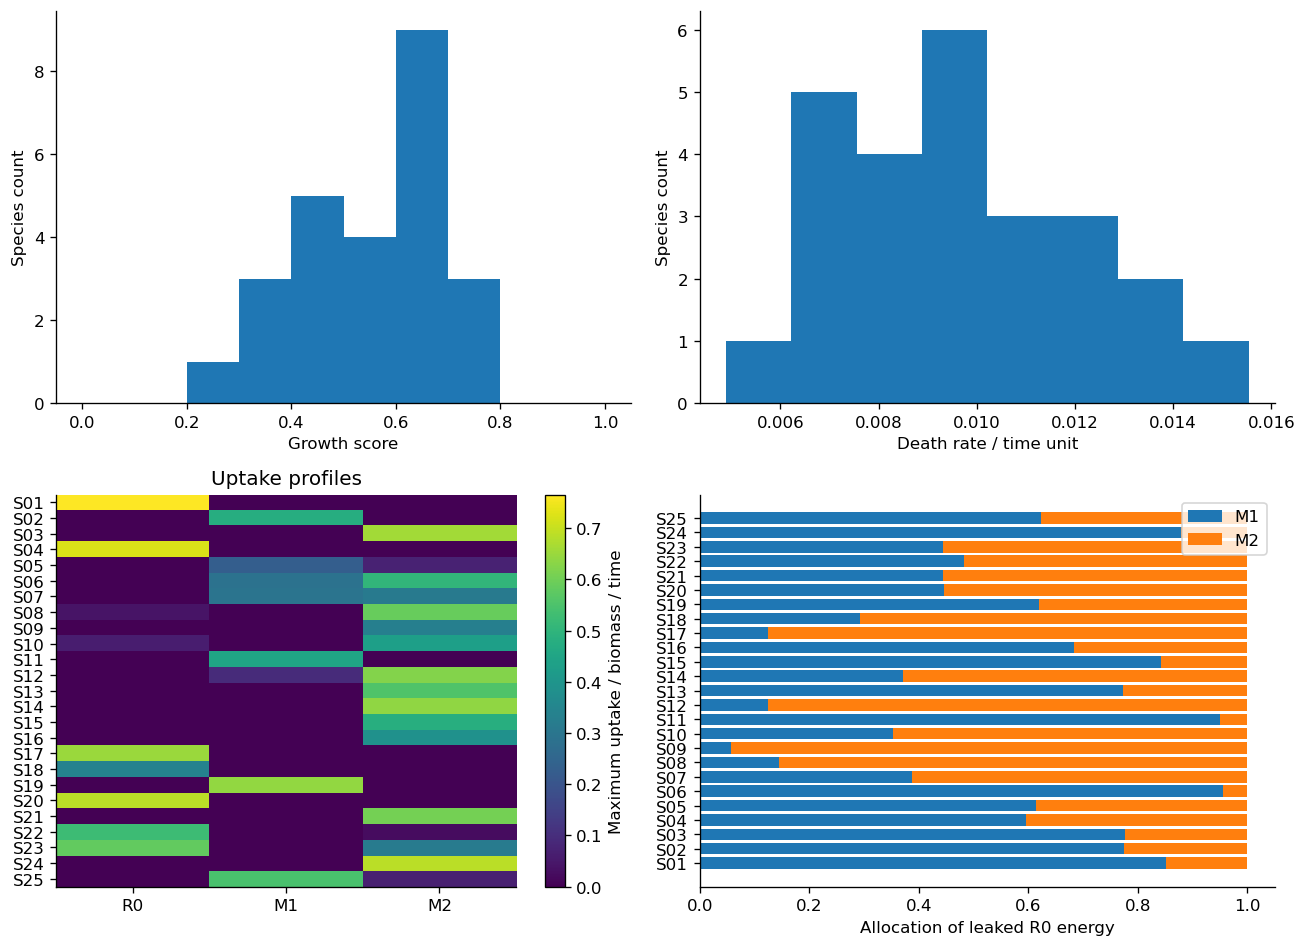

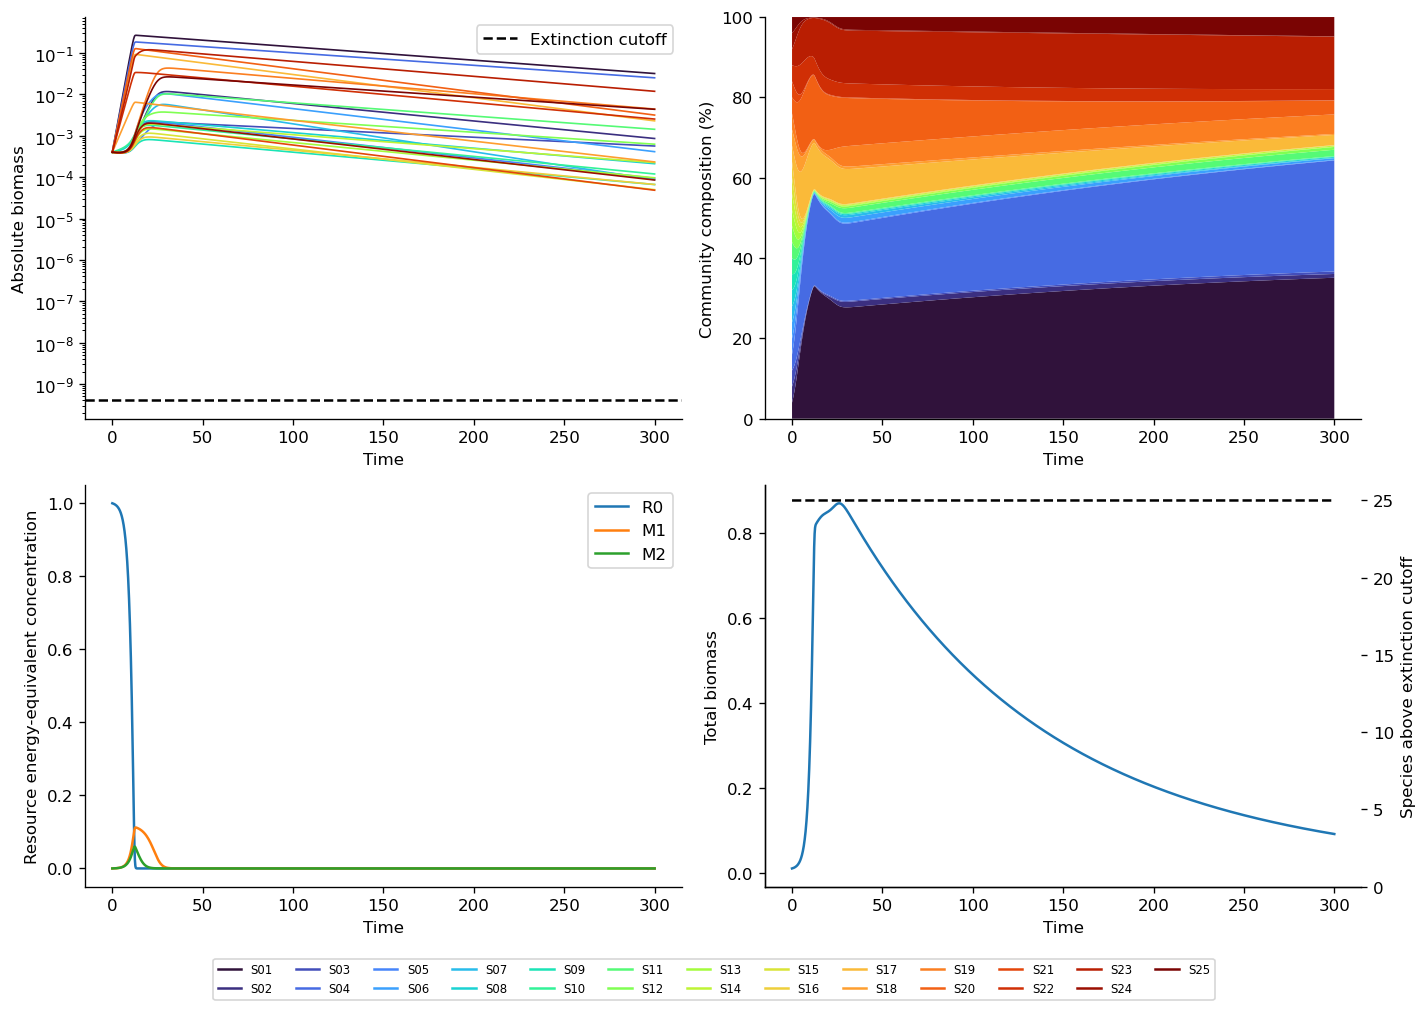

In [4]:
for path in figures[:2]:
    display(Image(filename=str(path)))

## Growth, death, trait associations and diversity
Gross growth depends on food availability. Net growth subtracts constant death. Biomass death flux changes because living biomass changes. Trait–outcome scatter plots describe this community; they do not isolate causal effects.

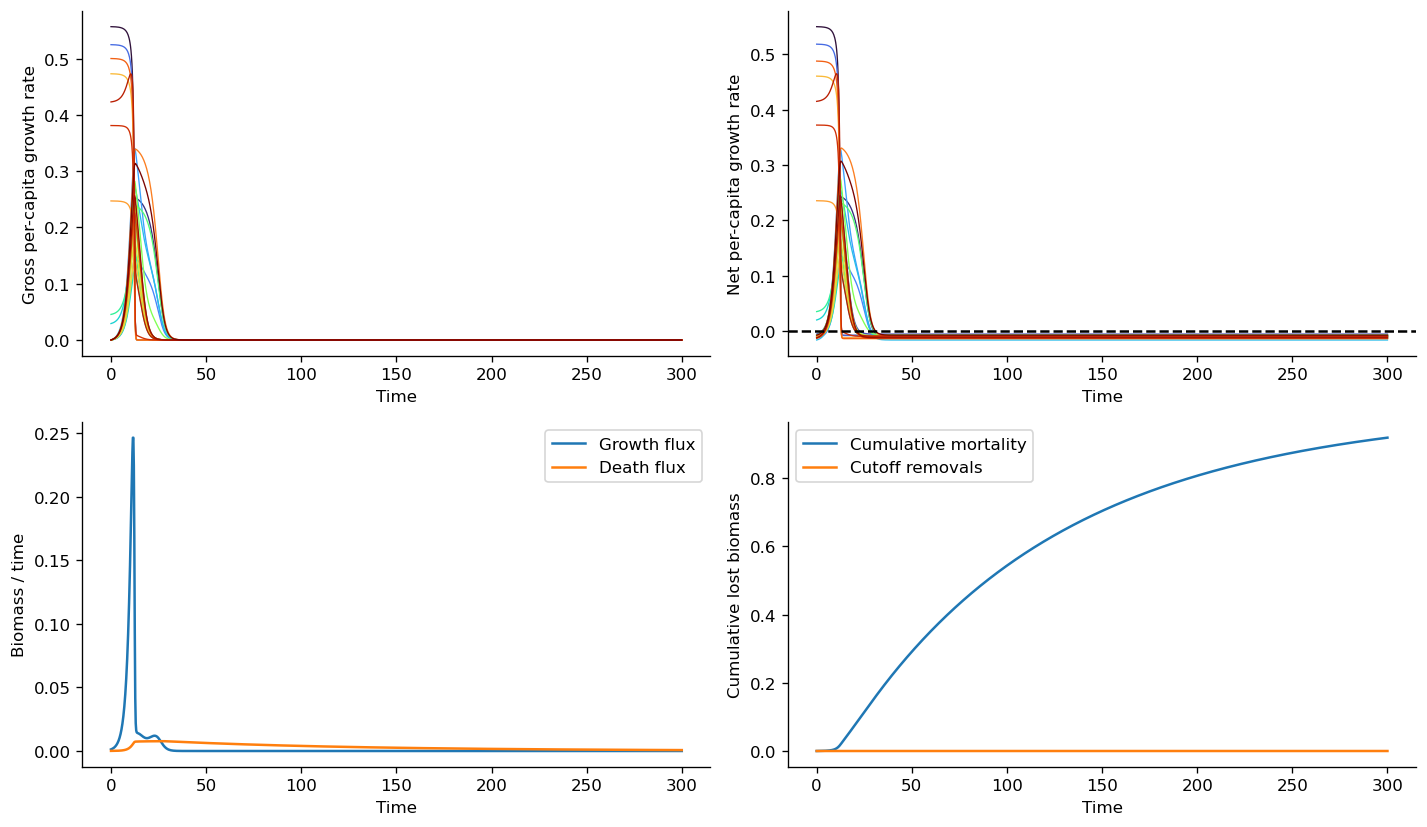

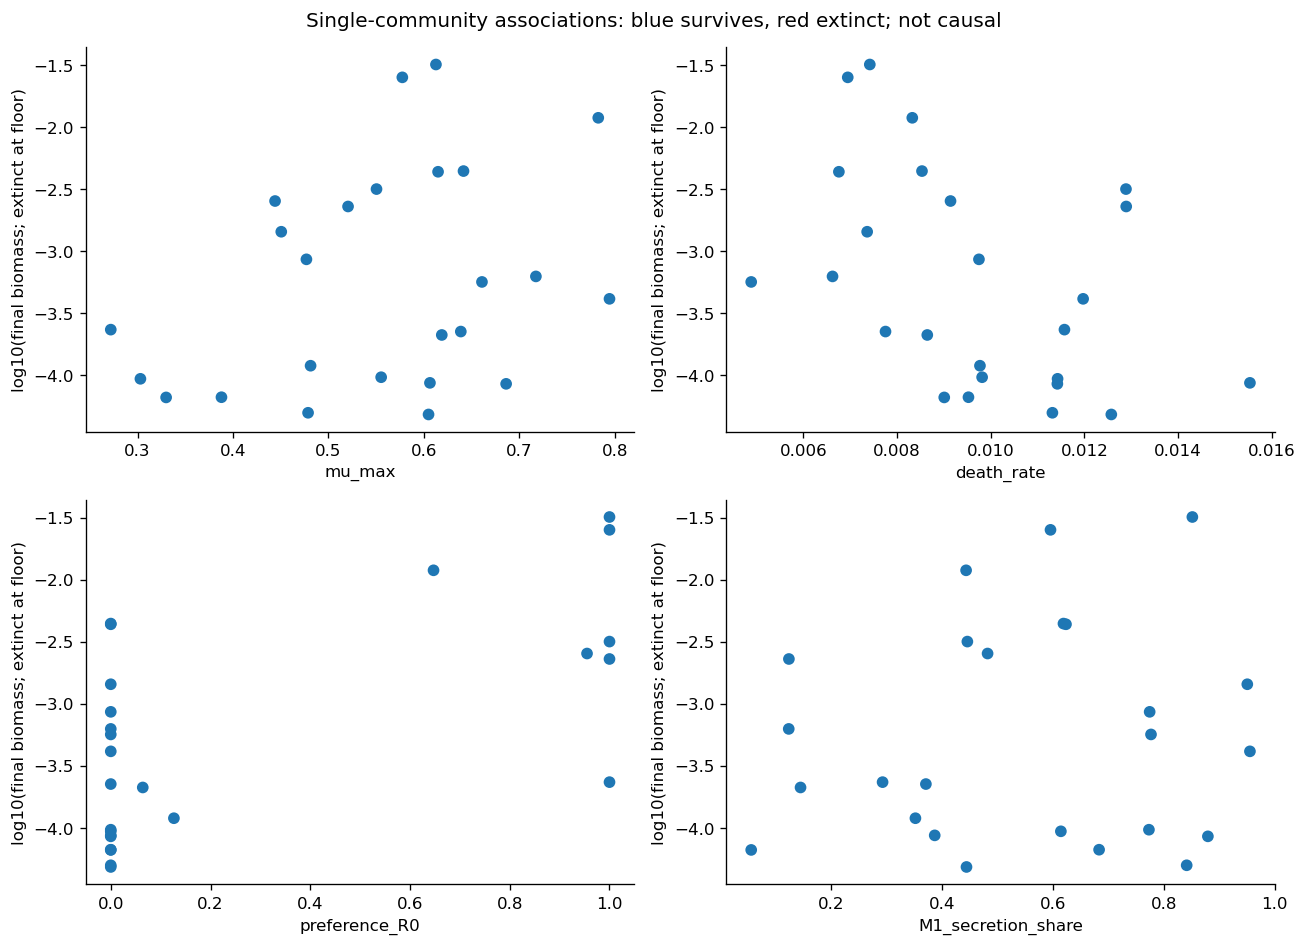

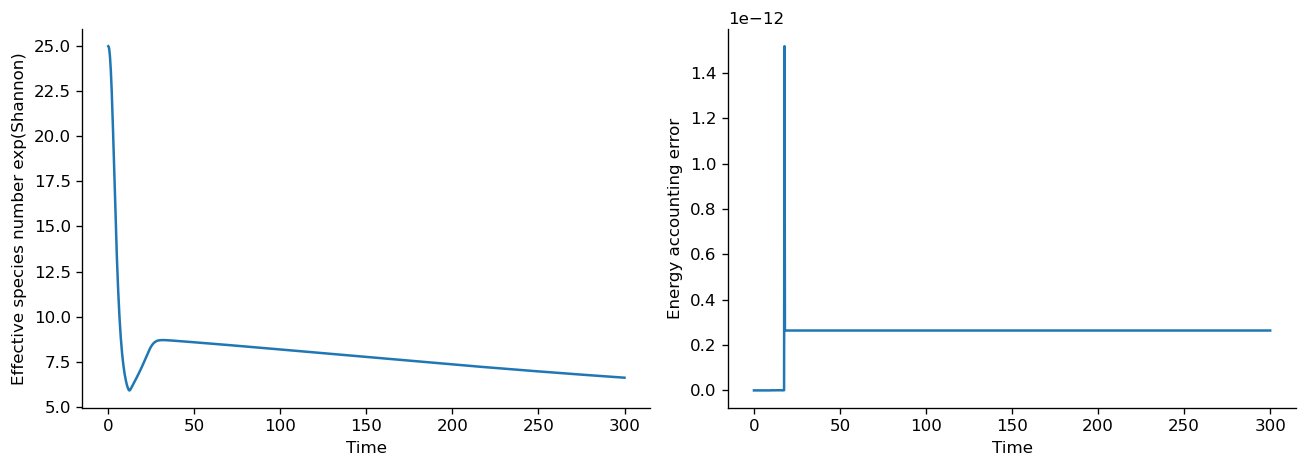

In [5]:
for path in figures[2:]:
    display(Image(filename=str(path)))

## Extinction-threshold sensitivity
All random draws are held fixed. The thresholds are numerical conventions rather than universal biological detection limits.

In [6]:
sensitivity=[]
for fraction in [1e-4, 1e-6, 1e-8]:
    pp=generate(replace(config, extinction_fraction=fraction))
    rr=simulate(pp)
    sensitivity.append({"cutoff_fraction":fraction,"survivors":int((rr["N"][-1]>0).sum()),"final_total_biomass":rr["N"][-1].sum(),"max_budget_error":abs(rr["budget_error"]).max()})
sensitivity=pd.DataFrame(sensitivity)
sensitivity.to_csv(out/"cutoff_sensitivity.csv",index=False)
display(sensitivity)

,cutoff_fraction,survivors,final_total_biomass,max_budget_error
0,1.000000e-04,25,0.091088,1.517453e-12
1,1.000000e-06,25,0.091088,1.517453e-12
2,1.000000e-08,25,0.091088,1.517453e-12


## Repeat over 20 random communities
Species within each community interact. These pooled correlations are descriptive, and the 500 rows are not 500 independent experiments. Biomass-time integral captures performance even if all species remain above the extinction cutoff.

,survivors,final_biomass
community_seed,,
42,25,0.091088
43,25,0.147187
44,25,0.080942
45,25,0.049146
46,25,0.052376
47,25,0.044369
48,25,0.075780
49,25,0.059384
50,25,0.170333


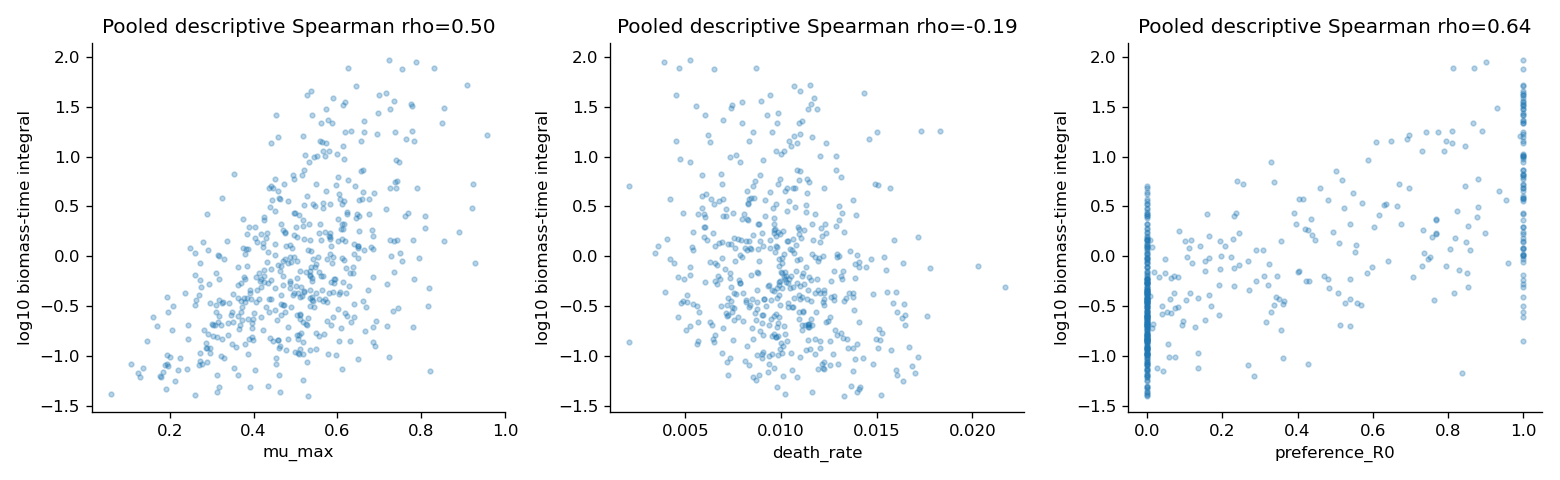

In [7]:
repeated=ensemble(config,replicates=20)
repeated.to_csv(out/"ensemble_species_summary.csv",index=False)
display(repeated.groupby("community_seed").agg(survivors=("survived","sum"),final_biomass=("final_biomass","sum")))
display(Image(filename=str(ensemble_plot(repeated,out))))

## Interpretation and next experiments
Compare absolute biomass, shares, and growth rates together. Final survival depends on observation time, death scale and cutoff; it does not prove permanent coexistence. Later experiments can compare no leakage versus leakage, altered death scales, or an imposed growth-survival tradeoff using the same community draws. A chemical conversion/necromass model would be a substantive extension, not just a parameter change.